# 06 · Market-analysis pipeline: public data → observational analyses

**Process.**

1. **Collection (M10).** A curated list of public podcast channels is tracked with the YouTube Data
   API: a one-off backfill of each channel's uploads, then a daily pull of video statistics within
   a quota budget. RSS is used to discover new videos cheaply.
2. **Private flows (M11, M12).** The owner's own channel is connected with OAuth: the Analytics API
   gives views and retention, and the Reporting API gives impressions and CTR. Both were validated
   end to end. The test channel's reach reports were still empty, so no real CTR labels exist yet
   (report, *Limitations*).
3. **Analyses.** The worker precomputes them into `insight_results` whenever the data's fingerprint
   changes (decision 0023), for three formats: long videos (> 3 min), shorts and all:
   - an **age-adjusted residual** of views per video: a log-views vs. log-age fit per channel;
   - **channel clustering**: k-means on standardised channel features, with k chosen by silhouette;
   - **drivers**: the Spearman correlation of the residual with video features, with bootstrap CIs;
   - **keyword lift**: the mean residual of videos with a title word minus those without, with a
     Welch CI.

| | |
|---|---|
| Report | §3 *Market-Analysis Pipeline*; §4 *Market Data and Analyses* |
| Code | `backend/app/market/` (collection), `backend/app/youtube_oauth/`, `backend/app/analytics/`, `backend/app/reporting/`, `backend/app/insights/` (analyses) |
| Decisions | 0015 (market pipeline v0), 0017 (OAuth + Analytics), 0018 (Reporting API), 0022–0023 (dashboards, precomputed insights) |

This notebook loads the market frame with the app's own loader and **recomputes every analysis**
with the same functions as the worker. It then compares the result with the stored
`insight_results` and with the report. The channels are public, and they are shown by number.

In [1]:
import time

from yts_nb import *  # first: puts backend/ on sys.path
from app.insights import analysis, store
from app.insights.frame import load_market_frame

## 1. What has been collected

In [2]:
coll = await sql("""
    select (select count(*) from market_channels)                                as channels,
           (select count(*) from market_channels where active)                   as active_channels,
           (select count(*) from market_channels where backfill_completed_at is not null) as backfilled,
           (select count(*) from market_videos)                                  as videos,
           (select count(*) from market_videos where unavailable_since is not null) as unavailable,
           (select count(*) from market_video_snapshots)                         as snapshots,
           (select count(distinct snapshot_date) from market_video_snapshots)    as snapshot_days,
           (select min(snapshot_date) from market_video_snapshots)               as first_snapshot,
           (select max(snapshot_date) from market_video_snapshots)               as last_snapshot
""")
coll.T.rename(columns={0: "value"})

,value
channels,22
active_channels,21
backfilled,21
videos,47277
unavailable,0
snapshots,49538
snapshot_days,4
first_snapshot,2026-11-07
last_snapshot,2026-11-21


In [3]:
per_day = await sql("select snapshot_date, count(*) as snapshots from market_video_snapshots group by 1 order by 1")
via = await sql("select discovered_via, count(*) as videos from market_videos group by 1 order by 2 desc")
print(via.to_string(index=False))
private = await sql("""
    select (select count(*) from oauth_credentials)  as oauth_connections,
           (select count(*) from analytics_videos)   as analytics_videos,
           (select count(*) from reporting_jobs)     as reporting_jobs,
           (select count(*) from reporting_reports)  as reporting_reports_stored
""")
print(private.T.rename(columns={0: "rows"}).to_string())

discovered_via  videos
      backfill   47012
           rss     265
                          rows
oauth_connections            1
analytics_videos            10
reporting_jobs               1
reporting_reports_stored     0


21 channels are active and backfilled, as in the report. The private-flow tables show that the
OAuth and Reporting jobs are wired up. The 33 header-only reach
reports downloaded during M12's live test (report, *Collection*) are not in this database
(0 rows). Either way they held no data rows, so there is no CTR data to analyse.

## 2. Recompute every analysis

In [4]:
async with session_factory() as db:
    frame = await load_market_frame(db)
print(f"market frame: {len(frame):,} videos with a snapshot, {len(frame.channel_titles)} channels, "
      f"snapshot date {frame.snapshot_date}")
t0 = time.perf_counter()
computed = store._compute_market(frame)
print(f"{len(computed)} analyses (5 × 3 formats) in {time.perf_counter() - t0:.1f} s "
      f"(the report gives about 9.5 s)")
results = {(name, fmt): payload for name, fmt, payload, _ in computed}

stored = await sql("select name, format, payload, computed_at from insight_results where name <> 'channel'")
same = 0
for r in stored.itertuples():
    if store.clean_json(results[(r.name, r.format)]) == r.payload:
        same += 1
print(f"identical to the stored insight_results: {same} of {len(stored)} "
      f"(stored at {stored.computed_at.max():%Y-%m-%d %H:%M} UTC)")

market frame: 47,277 videos with a snapshot, 22 channels, snapshot date 2026-11-21


15 analyses (5 × 3 formats) in 8.6 s (the report gives about 9.5 s)
identical to the stored insight_results: 15 of 15 (stored at 2026-11-21 18:06 UTC)


## 3. The age-adjusted residual

Views grow with age, and channels differ in size, so raw views cannot be compared. Each channel
gets a least-squares fit log10(views + 1) = a + b·log10(age in days). A video's residual is its
distance to that line: +0.3 means about twice the views expected for its channel and age. Every
analysis below works on this residual.

long videos: 25,473; per-channel fits: slope median -0.32, R² median 0.12 (range 0.00–0.30)


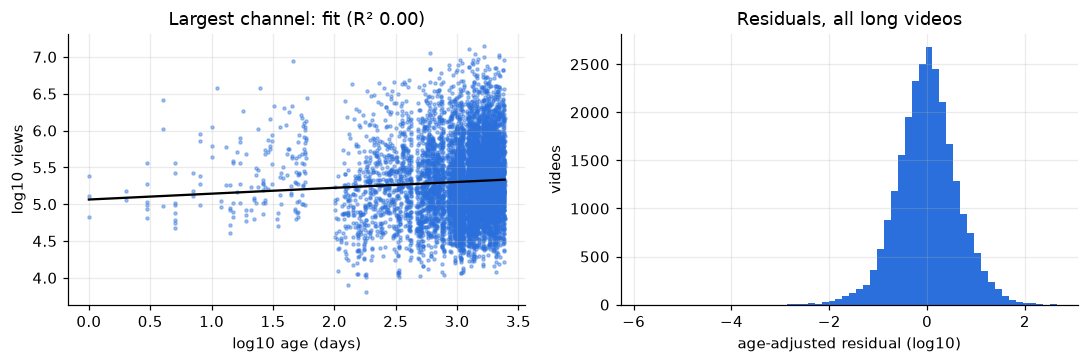

In [5]:
mask = analysis.select_format(frame, "long")
ages = analysis.age_days(frame)
resid = analysis.residuals(frame, mask)
fits = []
for cid in np.unique(frame.channel_ids[mask]):
    m = mask & (frame.channel_ids == cid)
    f = analysis.fit_log_age(ages[m], frame.views[m])
    fits.append({"channel": f"ch{len(fits) + 1:02d}", "videos": int(m.sum()), "slope": f.slope, "r2": f.r2})
fits = pd.DataFrame(fits)
print(f"long videos: {mask.sum():,}; per-channel fits: slope median {fits.slope.median():.2f}, "
      f"R² median {fits.r2.median():.2f} (range {fits.r2.min():.2f}–{fits.r2.max():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
cid_big = np.unique(frame.channel_ids[mask])[fits.videos.idxmax()]
m = mask & (frame.channel_ids == cid_big)
axes[0].scatter(np.log10(ages[m]), np.log10(frame.views[m] + 1), s=4, alpha=0.4)
f = analysis.fit_log_age(ages[m], frame.views[m])
xs = np.linspace(np.log10(ages[m]).min(), np.log10(ages[m]).max(), 10)
axes[0].plot(xs, f.intercept + f.slope * xs, color="black", lw=1.5)
axes[0].set(xlabel="log10 age (days)", ylabel="log10 views", title=f"Largest channel: fit (R² {f.r2:.2f})")
axes[1].hist(resid[mask], bins=60, color=COLORS[0])
axes[1].set(xlabel="age-adjusted residual (log10)", ylabel="videos", title="Residuals, all long videos")
plt.tight_layout()
plt.show()

## 4. Channel clustering

k = 2, silhouette = 0.21, PCA variance explained 37% + 25%
silhouette (long videos): recomputed 0.2125 matches the report (0.2100) | report k = 2


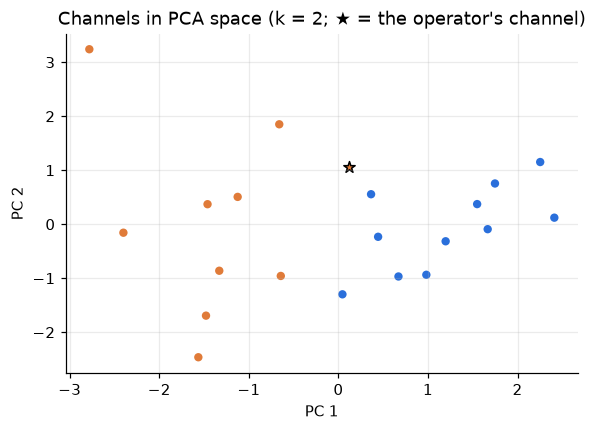

,cluster,channels,log_median_views,like_rate,comment_rate,uploads_per_week_90d,median_duration_min,views_spread
0,0,11,5.67,0.02,0.0,1.56,87.07,0.76
1,1,10,4.49,0.02,0.0,2.22,35.35,0.96


In [6]:
cl = results[("clusters", "long")]
print(f"k = {cl['k']}, silhouette = {cl['silhouette']:.2f}, PCA variance explained "
      f"{cl['explained_variance'][0]:.0%} + {cl['explained_variance'][1]:.0%}")
print(compare("silhouette (long videos)", cl["silhouette"], 0.21, tol=0.005), "| report k = 2")
fig, ax = plt.subplots(figsize=(6, 4))
for p in cl["points"]:
    ax.scatter(p["x"], p["y"], color=COLORS[p["cluster"]], s=60 if p["own"] else 30,
               marker="*" if p["own"] else "o", edgecolor="black" if p["own"] else "none")
ax.set(xlabel="PC 1", ylabel="PC 2", title=f"Channels in PCA space (k = {cl['k']}; ★ = the operator's channel)")
plt.show()
pd.DataFrame([{"cluster": c["id"], "channels": c["size"], **c["profile"]} for c in cl["clusters"]]).round(2)

A silhouette of about 0.2 means a weak structure. The interface says so, so that the map is not
over-read.

## 5. What is associated with more views (drivers)

Spearman, video length: recomputed 0.2968 matches the report (0.3000)
Spearman, number in title: recomputed 0.1574 matches the report (0.1600)
Spearman, question in title: recomputed -0.0621 matches the report (-0.0600)


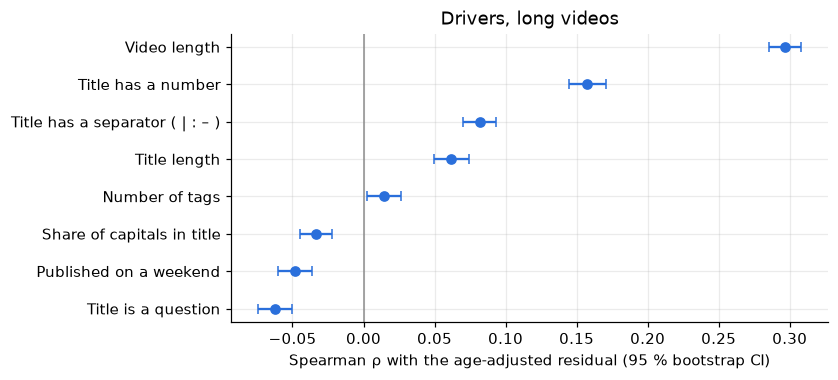

,rho,ci_low,ci_high,n
label,,,,
Title is a question,-0.062,-0.074,-0.050,25473
Published on a weekend,-0.048,-0.060,-0.036,25473
Share of capitals in title,-0.034,-0.045,-0.022,25473
Number of tags,0.015,0.003,0.026,25473
Title length,0.062,0.049,0.074,25473
Title has a separator ( | : – ),0.082,0.070,0.093,25473
Title has a number,0.157,0.144,0.170,25473
Video length,0.297,0.286,0.308,25473


In [7]:
dr = pd.DataFrame(results[("drivers", "long")]["correlations"]).set_index("label")
print(compare("Spearman, video length", dr.loc["Video length", "rho"], 0.30, tol=0.005))
print(compare("Spearman, number in title", dr.loc["Title has a number", "rho"], 0.16, tol=0.005))
print(compare("Spearman, question in title", dr.loc["Title is a question", "rho"], -0.06, tol=0.005))
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(dr))
ax.errorbar(dr.rho, y, xerr=[dr.rho - dr.ci_low, dr.ci_high - dr.rho], fmt="o", color=COLORS[0], capsize=3)
ax.axvline(0, color=GREY, lw=1)
ax.set_yticks(y, dr.index)
ax.set(xlabel="Spearman ρ with the age-adjusted residual (95 % bootstrap CI)", title="Drivers, long videos")
plt.show()
dr[["rho", "ci_low", "ci_high", "n"]].round(3)

## 6. Keyword lift

25,473 titles; candidates must appear in ≥ 40 videos of ≥ 3 channels, and no channel may hold more than half of them


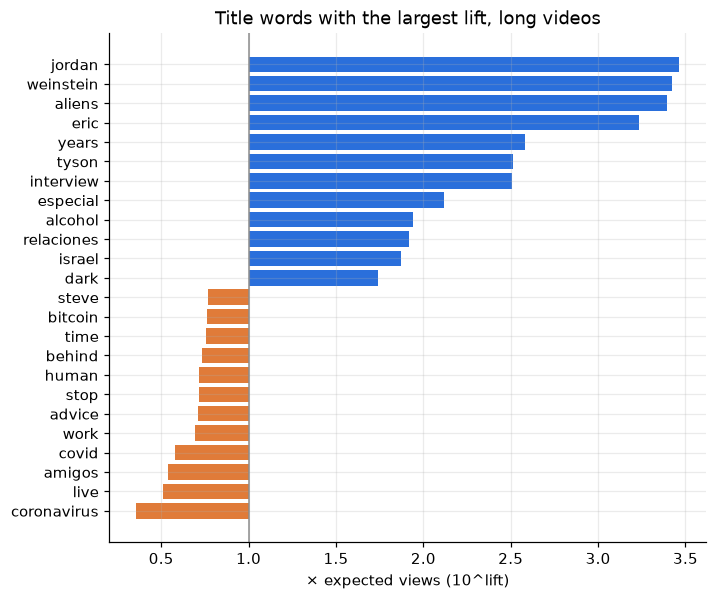

,token,videos,channels,lift,ci_low,ci_high,multiplier
0,jordan,114,9,0.539,0.392,0.687,3.463
1,weinstein,67,8,0.534,0.345,0.723,3.422
2,aliens,55,9,0.531,0.366,0.695,3.393
3,eric,62,9,0.509,0.305,0.714,3.232
4,years,71,7,0.412,0.253,0.571,2.582
5,tyson,48,9,0.400,0.216,0.584,2.511
6,interview,56,8,0.399,0.212,0.586,2.507
7,especial,77,7,0.326,0.167,0.485,2.119
8,alcohol,51,7,0.288,0.127,0.449,1.941
9,relaciones,62,4,0.282,0.138,0.426,1.915


In [8]:
kw = results[("keywords", "long")]
lift = pd.DataFrame(kw["positive"] + kw["negative"]).sort_values("lift")
print(f"{kw['n']:,} titles; candidates must appear in ≥ 40 videos of ≥ 3 channels, and no channel may hold more than half of them")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(lift.token, lift.multiplier - 1, left=1, color=[COLORS[0] if v > 0 else COLORS[1] for v in lift.lift])
ax.axvline(1, color=GREY, lw=1)
ax.set(xlabel="× expected views (10^lift)", title="Title words with the largest lift, long videos")
plt.show()
lift[["token", "videos", "channels", "lift", "ci_low", "ci_high", "multiplier"]].round(3).iloc[::-1]

## Summary

- The collection covers the tracked public channels, with daily snapshots within the quota. The
  private OAuth and Reporting flows are wired up but have no real reach data yet.
- The recomputation reproduces the stored `insight_results` exactly (15 of 15). It also matches the
  report: k = 2 with a silhouette of 0.21, and driver correlations of 0.30, 0.16 and −0.06.
- All of these are **associations in observational data**. They describe what drew audiences in
  the past, not what causes views. The interface states this next to each chart.